# Delivery Time Prediction with TabPFN-3.5

This notebook evaluates TabPFN-3.5 (tabpfn 10.2.0) on the Meituan delivery dataset using the Manhattan distance protocol and the two operational feature sets: order checkout (`FEATURES_REDUCED`, 13 features) and courier dispatch (`FEATURES_COMPLETE`, 25 features). Data preparation uses `data/dataloader.py`, while model configuration, subsampled ensemble fitting, KV-cached inference, checkpoint persistence, and SHA-256 audit manifests are imported from `models/tabpfn_model.py`.

## Stage 1: Environment Setup and Imports

This section checks package versions and hardware acceleration, sets the global random seed, and configures runtime parameters. On CPU, each ensemble member uses 3,000 training rows with `n_estimators=8` (the native TabPFN-3.5 default) and `fit_mode='fit_with_cache'`. On CUDA GPUs, the configuration scales automatically to 5,000 training rows per member and full test-set evaluation.

In [1]:
import json
import sys
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tabpfn
import torch
from sklearn.ensemble import RandomForestRegressor

sys.path += ['../data', '../models']
from dataloader import (
    BASELINE,
    FEATURES_COMPLETE,
    FEATURES_REDUCED,
    TARGET,
    load_meituan,
)
from tabpfn_model import (
    TabPFNConfig,
    TabPFNModel,
    compute_metrics,
    sample_dataframe,
)

SEED = 42
CKPT_DIR = Path('../models/checkpoints')
CKPT_DIR.mkdir(parents=True, exist_ok=True)
HAS_CUDA = torch.cuda.is_available()

if HAS_CUDA:
    TRAIN_SAMPLE_SIZE = 5000
    N_ENSEMBLE = 5
    N_ESTIMATORS = 'auto'
    TEST_EVAL_SIZE = None
else:
    TRAIN_SAMPLE_SIZE = 3000
    N_ENSEMBLE = 3
    N_ESTIMATORS = 8
    TEST_EVAL_SIZE = 2000

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
device_label = torch.cuda.get_device_name(0) if HAS_CUDA else 'CPU'
print(f'tabpfn version: {tabpfn.__version__} | torch: {torch.__version__} | device: {device_label}')
print(f'Config: sample_size={TRAIN_SAMPLE_SIZE}, n_ensemble={N_ENSEMBLE}, '
      f'n_estimators={N_ESTIMATORS}, test_eval={TEST_EVAL_SIZE}')

tabpfn version: 10.2.0 | torch: 2.14.1+cpu | device: CPU
Config: sample_size=3000, n_ensemble=3, n_estimators=8, test_eval=2000


## Stage 2: Data Loading and Variance-Matched Partitioning

We load three partitions using `load_meituan` with `distance='manhattan'`: the standard random `70_30` split, the `stratified_district` split, and the out-of-distribution `district` split. When evaluating on CPU with `TEST_EVAL_SIZE=2000`, test subsets are stratified across 20 target quantiles so that the evaluation sample preserves the exact target variance of the full test set, preventing artificial R2 distortion. Training subsamples are likewise stratified across 20 target quantiles (or by district in the stratified split) to preserve tail coverage.

In [2]:
SPLIT_NAMES = ['70_30', 'stratified_district', 'district']
splits = {}
summary_rows = []

for split_name in SPLIT_NAMES:
    tr_df, val_df, te_df = load_meituan(
        split=split_name,
        distance='manhattan',
        seed=SEED,
        verbose=False,
    )
    tr_df = tr_df.copy()
    te_df = te_df.copy()
    tr_df['_y_bin'] = pd.qcut(tr_df[TARGET], q=20, labels=False, duplicates='drop')
    te_df['_y_bin'] = pd.qcut(te_df[TARGET], q=20, labels=False, duplicates='drop')

    te_eval, _, te_hash = sample_dataframe(
        te_df, TEST_EVAL_SIZE, stratify_col='_y_bin', seed=SEED
    )
    strat_col = 'district_id' if split_name == 'stratified_district' else '_y_bin'
    splits[split_name] = {
        'train': tr_df,
        'val': val_df,
        'test_full': te_df,
        'test_eval': te_eval,
        'test_eval_sha256': te_hash,
        'stratify_col': strat_col,
    }
    summary_rows.append({
        'split': split_name,
        'train_rows': len(tr_df),
        'test_full_rows': len(te_df),
        'test_eval_rows': len(te_eval),
        'test_full_var': round(float(np.var(te_df[TARGET])), 2),
        'test_eval_var': round(float(np.var(te_eval[TARGET])), 2),
        'test_eval_mean_min': round(float(te_eval[TARGET].mean()), 3),
    })

pd.DataFrame(summary_rows)

,split,train_rows,test_full_rows,test_eval_rows,test_full_var,test_eval_var,test_eval_mean_min
0,70_30,377104,53872,2000,139.68,138.32,29.487
1,stratified_district,377104,53872,2000,139.06,147.64,29.542
2,district,380518,79023,2000,120.85,117.61,29.306


## Stage 3: Platform Baseline Reference

We compute the error metrics of the Meituan platform estimate (`meituan_baseline_min`) on each variance-matched test set to establish the operational baseline.

In [3]:
baseline_rows = []
for split_name, part in splits.items():
    te_eval = part['test_eval']
    m = compute_metrics(te_eval[TARGET], te_eval[BASELINE])
    baseline_rows.append({
        'split': split_name,
        'stage': 'platform_baseline',
        'model': 'Meituan App Estimate',
        'test_MAE': round(m['MAE'], 3),
        'test_RMSE': round(m['RMSE'], 3),
        'test_R2': round(m['R2'], 4),
        'runtime_s': 0.0,
    })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df

,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,platform_baseline,Meituan App Estimate,9.623,11.823,-0.0106,0.0
1,stratified_district,platform_baseline,Meituan App Estimate,9.808,12.051,0.0164,0.0
2,district,platform_baseline,Meituan App Estimate,9.205,11.286,-0.0830,0.0


## Stage 4: TabPFN-3.5 Evaluation Across Partitions and Stages

We fit `TabPFNModel` (`model_version='v3.5'`, `n_estimators=8`, `fit_mode='fit_with_cache'`) on the primary `70_30` protocol for both `FEATURES_REDUCED` (13 features) and `FEATURES_COMPLETE` (25 features), and on `stratified_district` and `district` for `FEATURES_COMPLETE`. Every run persists a `.joblib` checkpoint, test predictions in `.parquet`, and a JSON audit manifest with SHA-256 hashes, then verifies deterministic reload (`max_reload_diff == 0.0`).

In [4]:
SCENARIOS = [
    ('70_30', 'reduced_checkout', FEATURES_REDUCED),
    ('70_30', 'complete_dispatch', FEATURES_COMPLETE),
    ('stratified_district', 'complete_dispatch', FEATURES_COMPLETE),
    ('district', 'complete_dispatch', FEATURES_COMPLETE),
]

BASE_CONFIG = TabPFNConfig(
    model_version='v3.5',
    n_ensemble=N_ENSEMBLE,
    sample_size=TRAIN_SAMPLE_SIZE,
    sampling_strategy='stratified',
    n_estimators=N_ESTIMATORS,
    fit_mode='fit_with_cache',
    n_preprocessing_jobs=1,
    batch_size=4096,
    aggregation='mean',
    ignore_pretraining_limits=True,
    seed=SEED,
    device='auto',
    verbose=True,
)

experiment_rows = []
audit_rows = []
predictions_store = {}

for split_name, stage_name, feat_cols in SCENARIOS:
    part = splits[split_name]
    tr_df = part['train']
    te_eval = part['test_eval']
    tag = f'{split_name}_{stage_name}'
    print(f'\n--- Running {tag} ({len(feat_cols)} features) ---')

    t0 = time.time()
    model = TabPFNModel(BASE_CONFIG).fit(
        tr_df,
        tr_df[TARGET],
        num_cols=feat_cols,
        stratify_col=part['stratify_col'],
        log_path=CKPT_DIR / f'tabpfn_{tag}_log.csv',
    )
    model.record_eval_target(te_eval[TARGET])
    test_preds, test_std = model.predict(te_eval, return_std=True)
    test_metrics = compute_metrics(te_eval[TARGET], test_preds)
    elapsed = round(time.time() - t0, 1)

    ckpt_path = CKPT_DIR / f'tabpfn_{tag}.joblib'
    model.save(
        ckpt_path,
        extra={'split': split_name, 'stage': stage_name, 'test_metrics': test_metrics},
    )

    reloaded = TabPFNModel.load(ckpt_path)
    audit_slice = te_eval.iloc[: min(256, len(te_eval))]
    max_reload_diff = float(np.max(np.abs(test_preds[: len(audit_slice)] - reloaded.predict(audit_slice))))
    assert max_reload_diff == 0.0, f'Non-deterministic reload diff: {max_reload_diff}'

    manifest = model.save_audit_manifest(
        CKPT_DIR / f'tabpfn_{tag}_audit.json',
        extra={
            'split': split_name,
            'stage': stage_name,
            'distance': 'manhattan',
            'test_eval_sha256': part['test_eval_sha256'],
            'test_metrics': test_metrics,
            'max_reload_diff': max_reload_diff,
            'runtime_s': elapsed,
        },
    )

    pd.DataFrame({
        'y_true': te_eval[TARGET].to_numpy(),
        'y_pred': test_preds,
        'y_std': test_std,
    }).to_parquet(CKPT_DIR / f'tabpfn_{tag}_predictions.parquet', index=False)

    predictions_store[(split_name, stage_name)] = {
        'y_true': te_eval[TARGET].to_numpy(),
        'y_pred': test_preds,
        'y_std': test_std,
    }

    audit_rows.append({
        'scenario': tag,
        'tabpfn_pkg': manifest['packages']['tabpfn'],
        'model_version': manifest['config']['model_version'],
        'n_estimators': manifest['config']['n_estimators'],
        'train_target_sha256': manifest['train_target_sha256'][:12],
        'eval_target_sha256': manifest['eval_target_sha256'][:12],
        'max_reload_diff': max_reload_diff,
    })

    experiment_rows.append({
        'split': split_name,
        'stage': stage_name,
        'model': f'TabPFN-{BASE_CONFIG.model_version} ({N_ENSEMBLE}x{TRAIN_SAMPLE_SIZE})',
        'test_MAE': round(test_metrics['MAE'], 3),
        'test_RMSE': round(test_metrics['RMSE'], 3),
        'test_R2': round(test_metrics['R2'], 4),
        'runtime_s': elapsed,
    })

results_df = pd.DataFrame(experiment_rows)
audit_df = pd.DataFrame(audit_rows)
display(results_df)
display(audit_df)


--- Running 70_30_reduced_checkout (13 features) ---
TabPFN (v3.5) | ensemble=3 x sample_size=3,000 (stratified) | n_estimators=8 | fit_mode=fit_with_cache | features=13 | device=cpu


  member  1/3 | n=3,000 | 75.0s


  member  2/3 | n=3,000 | 79.1s


  member  3/3 | n=3,000 | 80.0s


Checkpoint saved to ..\models\checkpoints\tabpfn_70_30_reduced_checkout.joblib


Audit manifest saved to ..\models\checkpoints\tabpfn_70_30_reduced_checkout_audit.json

--- Running 70_30_complete_dispatch (25 features) ---
TabPFN (v3.5) | ensemble=3 x sample_size=3,000 (stratified) | n_estimators=8 | fit_mode=fit_with_cache | features=25 | device=cpu


... (13 outputs left out)

Checkpoint saved to ..\models\checkpoints\tabpfn_district_complete_dispatch.joblib


Audit manifest saved to ..\models\checkpoints\tabpfn_district_complete_dispatch_audit.json


,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,reduced_checkout,TabPFN-v3.5 (3x3000),6.107,7.875,0.5517,373.0
1,70_30,complete_dispatch,TabPFN-v3.5 (3x3000),5.533,7.114,0.6341,424.2
2,stratified_district,complete_dispatch,TabPFN-v3.5 (3x3000),5.651,7.242,0.6448,421.5
3,district,complete_dispatch,TabPFN-v3.5 (3x3000),5.786,7.352,0.5404,424.6


,scenario,tabpfn_pkg,model_version,n_estimators,train_target_sha256,eval_target_sha256,max_reload_diff
0,70_30_reduced_checkout,10.2.0,v3.5,8,72617a3aba5f,f68a03b5de96,0.0
1,70_30_complete_dispatch,10.2.0,v3.5,8,72617a3aba5f,f68a03b5de96,0.0
2,stratified_district_complete_dispatch,10.2.0,v3.5,8,5100ed46d943,086a91f0e0a0,0.0
3,district_complete_dispatch,10.2.0,v3.5,8,d1731a32501f,f04580440e49,0.0


## Stage 5: Sample-Parity Comparison and Ensemble Scaling

To isolate the architectural advantage of TabPFN-3.5 from training sample volume, we compare TabPFN-3.5 against LightGBM trained on the exact same 3,000-row sample, as well as Random Forest and LightGBM trained on the full 377,104-row training set, all evaluated on the same `70_30` test set (`FEATURES_COMPLETE`, Manhattan distance). We also evaluate a 5-member TabPFN-3.5 ensemble (1 to 5 members at 3,000 rows each) to track cumulative ensemble convergence.

In [5]:
p70 = splits['70_30']
tr_70, val_70, te_70 = p70['train'], p70['val'], p70['test_eval']

# 1. Random Forest (full 377k)
t0 = time.time()
rf_full = RandomForestRegressor(
    n_estimators=50, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1
).fit(tr_70[FEATURES_COMPLETE], tr_70[TARGET])
m_rf = compute_metrics(te_70[TARGET], rf_full.predict(te_70[FEATURES_COMPLETE]))
t_rf = round(time.time() - t0, 1)

# 2. LightGBM (3,000 rows — equal sample parity)
tr_3k, _, _ = sample_dataframe(tr_70, 3000, stratify_col='_y_bin', seed=SEED)
t0 = time.time()
lgbm_3k = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
)
lgbm_3k.fit(
    tr_3k[FEATURES_COMPLETE], tr_3k[TARGET],
    eval_set=[(val_70.iloc[:1000][FEATURES_COMPLETE], val_70.iloc[:1000][TARGET])],
    callbacks=[lgb.early_stopping(30, verbose=False)],
)
m_lgbm_3k = compute_metrics(te_70[TARGET], lgbm_3k.predict(te_70[FEATURES_COMPLETE]))
t_lgbm_3k = round(time.time() - t0, 1)

# 3. LightGBM (full 377k)
t0 = time.time()
lgbm_full = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.05, num_leaves=31, random_state=SEED, n_jobs=-1, verbose=-1
)
lgbm_full.fit(
    tr_70[FEATURES_COMPLETE], tr_70[TARGET],
    eval_set=[(val_70[FEATURES_COMPLETE], val_70[TARGET])],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
m_lgbm_full = compute_metrics(te_70[TARGET], lgbm_full.predict(te_70[FEATURES_COMPLETE]))
t_lgbm_full = round(time.time() - t0, 1)

# 4. TabPFN-3.5 (1 to 5 members x 3,000 rows) on the same test set
cfg_5 = TabPFNConfig(
    model_version='v3.5',
    n_ensemble=5,
    sample_size=3000,
    sampling_strategy='stratified',
    n_estimators=8,
    fit_mode='fit_with_cache',
    n_preprocessing_jobs=1,
    batch_size=4096,
    seed=SEED,
    verbose=False,
)
m_tab5 = TabPFNModel(cfg_5).fit(
    tr_70, tr_70[TARGET],
    X_val=te_70, y_val=te_70[TARGET],
    num_cols=FEATURES_COMPLETE,
    stratify_col='_y_bin',
)
ens_curve_df = pd.DataFrame(m_tab5.history_)
ens_curve_df.to_csv(CKPT_DIR / 'tabpfn_ensemble_curve.csv', index=False)

m_tab1 = {'MAE': float(ens_curve_df.iloc[0]['val_mae']), 'RMSE': float(ens_curve_df.iloc[0]['val_rmse']), 'R2': float(ens_curve_df.iloc[0]['val_r2'])}
m_tab5_res = {'MAE': float(ens_curve_df.iloc[-1]['val_mae']), 'RMSE': float(ens_curve_df.iloc[-1]['val_rmse']), 'R2': float(ens_curve_df.iloc[-1]['val_r2'])}

parity_df = pd.DataFrame([
    {'model': 'LightGBM (3,000 rows)', 'train_rows': 3000, 'test_MAE': round(m_lgbm_3k['MAE'], 3), 'test_RMSE': round(m_lgbm_3k['RMSE'], 3), 'test_R2': round(m_lgbm_3k['R2'], 4), 'runtime_s': t_lgbm_3k},
    {'model': 'TabPFN-v3.5 (1x3,000)', 'train_rows': 3000, 'test_MAE': round(m_tab1['MAE'], 3), 'test_RMSE': round(m_tab1['RMSE'], 3), 'test_R2': round(m_tab1['R2'], 4), 'runtime_s': round(float(ens_curve_df.iloc[0]['cumulative_seconds']), 1)},
    {'model': 'TabPFN-v3.5 (5x3,000)', 'train_rows': 15000, 'test_MAE': round(m_tab5_res['MAE'], 3), 'test_RMSE': round(m_tab5_res['RMSE'], 3), 'test_R2': round(m_tab5_res['R2'], 4), 'runtime_s': round(float(ens_curve_df.iloc[-1]['cumulative_seconds']), 1)},
    {'model': 'Random Forest (377k rows)', 'train_rows': len(tr_70), 'test_MAE': round(m_rf['MAE'], 3), 'test_RMSE': round(m_rf['RMSE'], 3), 'test_R2': round(m_rf['R2'], 4), 'runtime_s': t_rf},
    {'model': 'LightGBM (377k rows)', 'train_rows': len(tr_70), 'test_MAE': round(m_lgbm_full['MAE'], 3), 'test_RMSE': round(m_lgbm_full['RMSE'], 3), 'test_R2': round(m_lgbm_full['R2'], 4), 'runtime_s': t_lgbm_full},
])
parity_df.to_csv(CKPT_DIR / 'tabpfn_parity_comparison.csv', index=False)
display(parity_df)
display(ens_curve_df[['member', 'val_mae', 'val_rmse', 'val_r2', 'cumulative_seconds']])

C:\Users\guilh\AppData\Roaming\Python\Python314\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


C:\Users\guilh\AppData\Roaming\Python\Python314\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,model,train_rows,test_MAE,test_RMSE,test_R2,runtime_s
0,"LightGBM (3,000 rows)",3000,5.806,7.494,0.5940,0.2
1,"TabPFN-v3.5 (1x3,000)",3000,5.567,7.162,0.6292,141.2
2,"TabPFN-v3.5 (5x3,000)",15000,5.525,7.100,0.6356,715.0
3,Random Forest (377k rows),377104,5.602,7.222,0.6229,34.1
4,LightGBM (377k rows),377104,5.200,6.710,0.6745,15.6


,member,val_mae,val_rmse,val_r2,cumulative_seconds
0,1,5.5668,7.1621,0.6292,141.24
1,2,5.5382,7.1332,0.6321,284.39
2,3,5.5330,7.1137,0.6341,427.24
3,4,5.5384,7.1094,0.6346,570.05
4,5,5.5249,7.0999,0.6356,714.97


## Stage 6: Results Summary and Diagnostic Plots

This final stage consolidates all metrics, saves `tabpfn_results.csv`, and generates diagnostic figures for ensemble scaling, sample-parity comparison, calibration, and residual distribution.

,split,stage,model,test_MAE,test_RMSE,test_R2,runtime_s
0,70_30,complete_dispatch,TabPFN-v3.5 (3x3000),5.533,7.114,0.6341,424.2
1,70_30,platform_baseline,Meituan App Estimate,9.623,11.823,-0.0106,0.0
2,70_30,reduced_checkout,TabPFN-v3.5 (3x3000),6.107,7.875,0.5517,373.0
3,district,complete_dispatch,TabPFN-v3.5 (3x3000),5.786,7.352,0.5404,424.6
4,district,platform_baseline,Meituan App Estimate,9.205,11.286,-0.0830,0.0
5,stratified_district,complete_dispatch,TabPFN-v3.5 (3x3000),5.651,7.242,0.6448,421.5
6,stratified_district,platform_baseline,Meituan App Estimate,9.808,12.051,0.0164,0.0


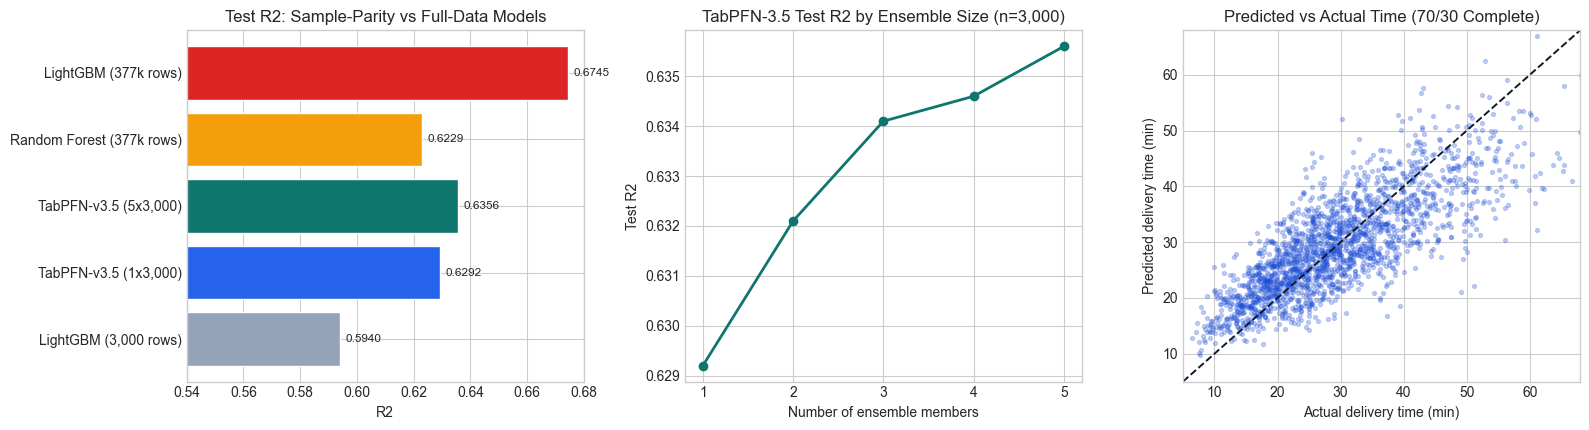

In [6]:
summary_table = pd.concat([baseline_df, results_df], ignore_index=True)
summary_table = summary_table.sort_values(['split', 'stage', 'test_MAE']).reset_index(drop=True)
summary_table.to_csv(CKPT_DIR / 'tabpfn_results.csv', index=False)
display(summary_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

# Panel 1: Sample-parity and full-data R2 comparison
colors_p = ['#94a3b8', '#2563eb', '#0f766e', '#f59e0b', '#dc2626']
axes[0].barh(parity_df['model'], parity_df['test_R2'], color=colors_p, edgecolor='white')
axes[0].set_xlim(0.54, 0.68)
axes[0].set_title('Test R2: Sample-Parity vs Full-Data Models')
axes[0].set_xlabel('R2')
for i, v in enumerate(parity_df['test_R2']):
    axes[0].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=8.5)

# Panel 2: TabPFN ensemble convergence (1 to 5 members x 3,000)
axes[1].plot(ens_curve_df['member'], ens_curve_df['val_r2'], marker='o', lw=2, color='#0f766e')
axes[1].set_title('TabPFN-3.5 Test R2 by Ensemble Size (n=3,000)')
axes[1].set_xlabel('Number of ensemble members')
axes[1].set_ylabel('Test R2')
axes[1].set_xticks(ens_curve_df['member'])

# Panel 3: Predicted vs Actual (70/30 Complete Dispatch)
pred_pack = predictions_store[('70_30', 'complete_dispatch')]
y_t, y_p = pred_pack['y_true'], pred_pack['y_pred']
axes[2].scatter(y_t, y_p, s=8, alpha=0.25, color='#1d4ed8')
lim = [5, min(140, float(np.percentile(y_t, 99.5)))]
axes[2].plot(lim, lim, ls='--', color='#0f172a', lw=1.4)
axes[2].set_xlim(lim)
axes[2].set_ylim(lim)
axes[2].set_title('Predicted vs Actual Time (70/30 Complete)')
axes[2].set_xlabel('Actual delivery time (min)')
axes[2].set_ylabel('Predicted delivery time (min)')

plt.tight_layout()
plt.savefig(CKPT_DIR / 'tabpfn_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()